Usamos la inversión en publicidad en TV, radio y diarios para predecir las ventas. El modelo aprendió cuánto aporta cada medio, y nos permite ver cuáles conviene más y estimar las ventas para una inversión dada.

- **Dataset:** Advertising (Kaggle). Cada fila es un mercado distinto (200 en total).
- **Y (lo que queremos predecir):** Sales – ventas, en miles de unidades.
- **X (lo que usamos para predecir):**
  - **Tv**: inversión en publicidad de TV (miles de dólares).
  - **Radio:** inversión en publicidad de radio (miles de dólares).
  - **Newspaper:** inversión en publicidad en diarios (miles de dólares).

## 1. Carga de datos y visualización de variables

In [ ]:
# importar librerias
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
# Carga del dataset

datos = pd.read_csv("advertising.csv")
print(datos.shape)
datos.head()


(200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [1]:
# valores nulos
print("Valores Nan por columna:")
print(datos.isna().sum())

Valores Nan por columna:


NameError: name 'datos' is not defined

In [ ]:
# Resumen estadístico de cada variable
datos.describe().round(2)

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,15.13
std,85.85,14.85,21.78,5.28
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,11.00
50%,149.75,22.90,25.75,16.00
75%,218.82,36.52,45.10,19.05
max,296.40,49.60,114.00,27.00


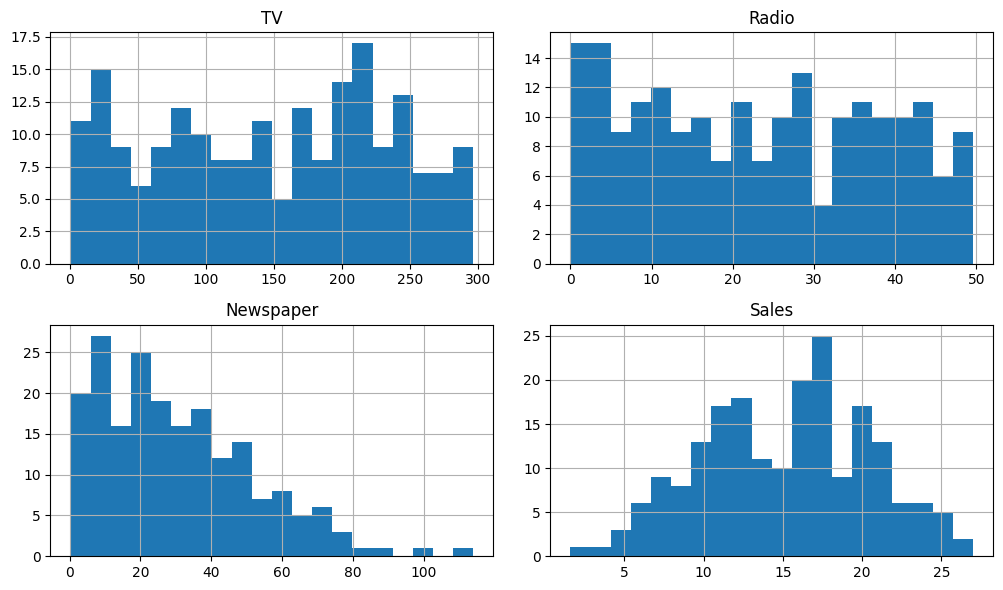

In [ ]:
# Un histograma para ver cómo se distribuye cada variable
datos.hist(bins=20, figsize=(10, 6))
plt.tight_layout()
plt.show()

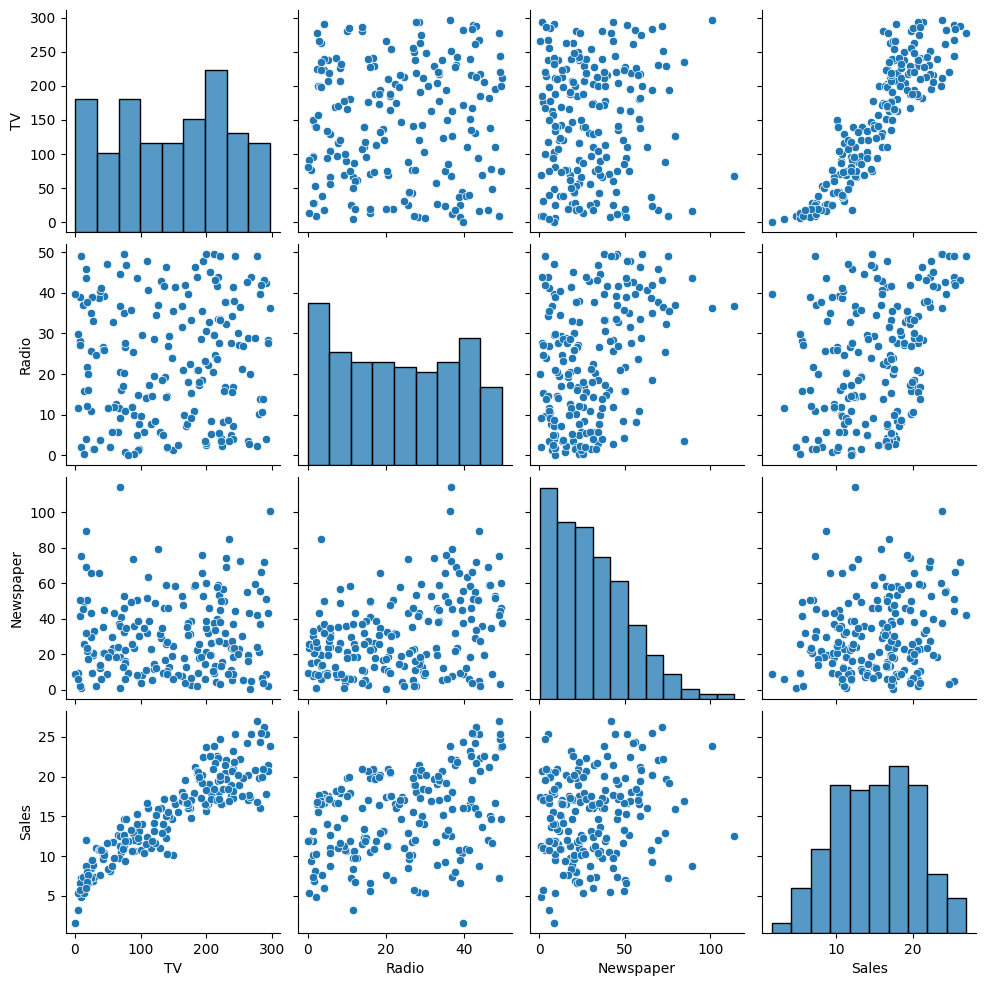

In [ ]:
# Pairplot para
sns.pairplot(datos[["TV", "Radio", "Newspaper", "Sales"]])
plt.show()

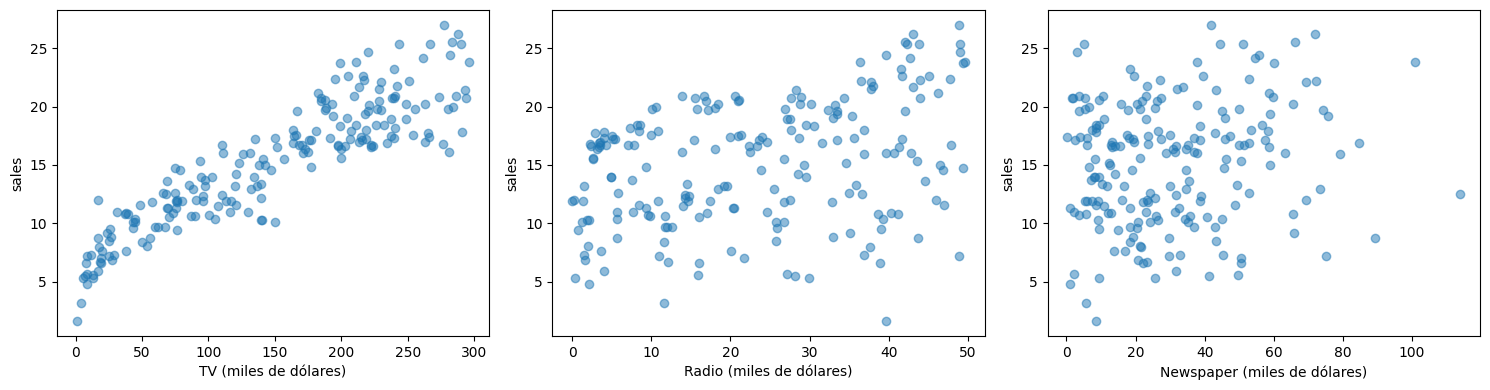

In [ ]:
# Comparamos cada feature contra Y (ventas). Si los puntos forman una línea, esa variable sirve para predecir. Lo que se busca es una diagonal
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(ejes, ["TV", "Radio", "Newspaper"]):
    ax.scatter(datos[col], datos["Sales"], alpha=0.5)
    ax.set_xlabel(col + " (miles de dólares)")
    ax.set_ylabel("sales")
plt.tight_layout()
plt.show()

In [ ]:
# Correlación: va de -1 a 1. Cuanto más cerca de 1 o -1, más relacionadas están las variables
datos.corr().round(2)

,TV,Radio,Newspaper,Sales
TV,1.00,0.05,0.06,0.90
Radio,0.05,1.00,0.35,0.35
Newspaper,0.06,0.35,1.00,0.16
Sales,0.90,0.35,0.16,1.00


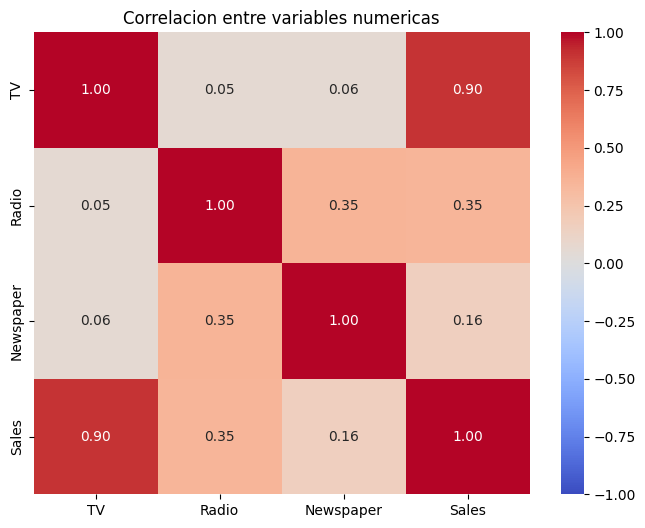

In [ ]:
# Heatmap para ver la correlacion entre variables

columnas = ["TV", "Radio", "Newspaper", "Sales"]
correlaciones = datos[columnas].corr()

plt.figure(figsize=(8,6))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlacion entre variables numericas")
plt.show()


## 2. Cambio de estructura de datos a matricial


In [ ]:
# Matriz con los features
X = datos[["TV", "Radio", "Newspaper"]].values

# Vector de lo que queremos predecir
y = datos["Sales"].values

print("X:", X.shape)
print("y:", y.shape)

X: (200, 3)
y: (200,)


## 3. Particionado de datos en Entrenamiento y Test


In [ ]:
# Particionado 80-20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=84)

print(X_train.shape)
print(X_test.shape)

(160, 3)
(40, 3)


## 4. Generación del modelo con los datos de Entrenamiento


In [ ]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

print("Intercepto: ", modelo.intercept_.round(2))
print("coeficiente: ", modelo.coef_.round(2))


Intercepto:  4.63
coeficiente:  [ 0.06  0.11 -0.  ]


In [ ]:
coeficientes = pd.DataFrame({
    "Variable": ["tv", "radio", "newspaper"],
    "Coeficiente": modelo.coef_.round(3)
})
coeficientes

,Variable,Coeficiente
0,tv,0.056
1,radio,0.106
2,newspaper,-0.004


In [ ]:
desvio = X_train.std(axis=0)

efecto = pd.DataFrame({
    "Variable": ["tv", "radio", "newspaper"],
    "Desvío de la inversión": desvio.round(2),
    "Cambio en ventas por 1 desvío": (modelo.coef_ * desvio).round(2)
})
efecto

,Variable,Desvío de la inversión,Cambio en ventas por 1 desvío
0,tv,84.18,4.70
1,radio,15.08,1.60
2,newspaper,21.88,-0.09


## 5. Evaluación del modelo con los datos de Entrenamiento


In [ ]:
# Prediccion
pred_train = modelo.predict(X_train)

# R2
r2_train = r2_score(y_train, pred_train)

#mae
mae_train = mean_absolute_error(y_train, pred_train)

#rmse
rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))

print("R²  :", round(r2_train, 3))
print("MAE :", round(mae_train, 3))
print("RMSE:", round(rmse_train, 3))

R²  : 0.906
MAE : 1.21
RMSE: 1.628


## 6. Evaluación del modelo con los datos de Test


In [ ]:
# Mismo procedimiento, pero con los datos que el modelo no vio al entrenar.
pred_test = modelo.predict(X_test)

# R2
r2_test = r2_score(y_test, pred_test)

# Mae
mae_test = mean_absolute_error(y_test, pred_test)

# Rmse
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print("R²  :", round(r2_test, 3))
print("MAE :", round(mae_test, 3))
print("RMSE:", round(rmse_test, 3))

R²  : 0.885
MAE : 1.413
RMSE: 1.749


Comparación de ambas evaluaciones:

In [ ]:
comparacion = pd.DataFrame({
    "Métrica": ["R²", "MAE", "RMSE"],
    "Entrenamiento": [r2_train, mae_train, rmse_train],
    "Test": [r2_test, mae_test, rmse_test]
}).round(3)
comparacion

,Métrica,Entrenamiento,Test
0,R²,0.906,0.885
1,MAE,1.210,1.413
2,RMSE,1.628,1.749


Gráfico de valores reales contra valores predichos en Test. Cuanto más cerca de la línea roja, mejor predice el modelo:

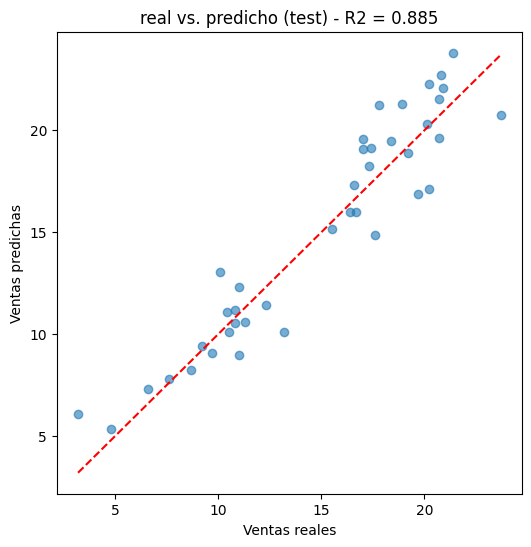

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Ventas reales")
plt.ylabel("Ventas predichas")
plt.title(f"real vs. predicho (test) - R2 = {r2_test:.3f}")
plt.show()

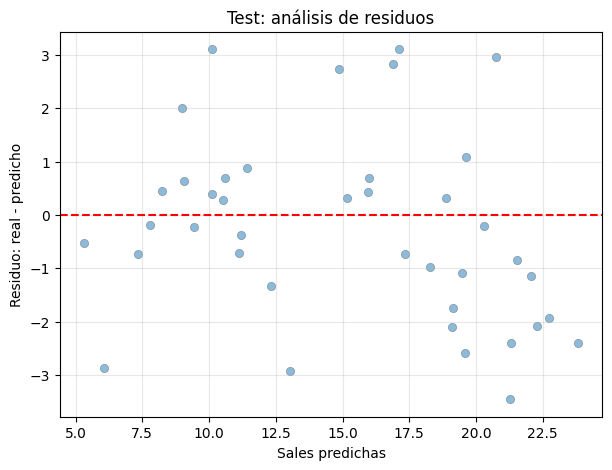

In [ ]:
residuos = y_test - pred_test
plt.figure(figsize=(7, 5))
plt.scatter(pred_test, residuos, alpha=0.5, edgecolor='k', linewidth=0.3)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Sales predichas')
plt.ylabel('Residuo: real - predicho')
plt.title('Test: análisis de residuos')
plt.grid(alpha=0.3)
plt.show()

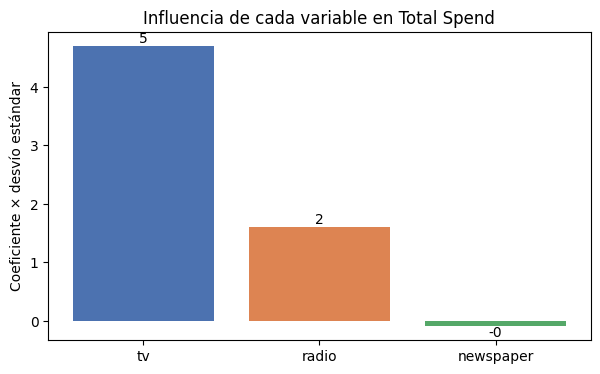

In [ ]:
# Importancia de cada variable (coeficientes × desvío estándar)
# Permite comparar variables con escalas distintas.
features = ["tv", "radio", "newspaper"]

plt.figure(figsize=(7, 4))
bars = plt.bar(features, efecto, color=['#4C72B0', '#DD8452', '#55A868'])
plt.bar_label(bars, fmt='%.0f')
plt.ylabel('Coeficiente × desvío estándar')
plt.title('Influencia de cada variable en Total Spend')
plt.show()